# 07. 발제안용 최종 그래프

발제안에 넣을 그림 5장을 `output/figures/final/`에 만든다.

**공통 규칙**
- 한국어 제목·축, 흰 배경, 300dpi
- 같은 색 체계: **무헤지 = 회색, 3년 만기 = 진한 파랑, 1년 롤링 = 주황, 기준선 = 빨간 점선**
- 제목은 "무엇을 보여주는지"가 아니라 **결론을 문장으로**

| 파일 | 내용 | 메시지 |
|---|---|---|
| `1_natural_hedge.png` | 금리 하락 시 b1 시나리오별 이자수익 변화 | 2 |
| `2_rate_paths.png` | 시장 선도금리와 시뮬레이션 경로 범위 | 방법 |
| `3_frontier_by_size.png` | 규모별 효율적 투자선 | 3·4 |
| `4_roll_vs_3y.png` | 1년 롤링 vs 3년 만기 (메인, 세계 C) | 3 |
| `5_robustness.png` | 설정 × 결론 ①~④ ○/× 표 | 강건성 |

## 준비
이 셀이 하는 일: 도구를 불러오고, 저장 폴더와 공통 색·글꼴 설정을 정한다.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC_DIR = PROJECT / "data" / "processed"
FINAL_DIR = PROJECT / "output" / "figures" / "final"
FINAL_DIR.mkdir(parents=True, exist_ok=True)
sys.path.append(str(PROJECT))

from src.plot_style import setup_plot_style, TEXT_SUB
from src.issuer_sim import load_market, load_issuer, simulate_rates, evaluate_strategies, pick_optimal
setup_plot_style()
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"})

GREY, BLUE, ORANGE, RED = "#8a8984", "#1c5cab", "#eb6834", "#d03b3b"   # 무헤지, 3년, 1년 롤링, 기준선
DPI = 300


def save(fig, name):
    fig.savefig(FINAL_DIR / name, dpi=DPI, bbox_inches="tight")
    plt.show()
    print("저장:", FINAL_DIR / name)

## 메인 설정 계산
이 셀이 하는 일: 05번과 같은 메인 설정(시장 일치 모형, g = 0, 전략 25개)으로 세 규모를 계산하고, Circle 수준은 세계 C(금리가 1.32%로 끌려가는 스트레스)로도 계산한다. 그림 2~4에 쓴다.

In [2]:
market = load_market()
C, S = load_issuer()
RSTAR = {"신규 진입": 4.5, "Circle 수준": 3.6, "대형": 2.5}
R = {size: C / ((1 - S) * rstar / 100) for size, rstar in RSTAR.items()}
A, SIGMA = 0.093, 0.64

paths = simulate_rates(market, A, SIGMA, n_paths=10_000, seed=42)
results = {size: evaluate_strategies(paths, market, R[size], C, S, RSTAR[size], A, SIGMA)[0] for size in RSTAR}

paths_c = simulate_rates(market, A, SIGMA, n_paths=10_000, seed=42, world="vasicek", b=1.32)
annual_main = evaluate_strategies(paths, market, R["Circle 수준"], C, S, 3.6, A, SIGMA, return_annual=True)[1]
annual_c = evaluate_strategies(paths_c, market, R["Circle 수준"], C, S, 3.6, A, SIGMA, return_annual=True)[1]

best_circle = pick_optimal(results["Circle 수준"])
print("Circle 수준 최적:", best_circle["전략"], f"| 비용 {best_circle['총 헤지 비용(백만$)'] / 100:.2f}억 달러")

Circle 수준 최적: K r*+0.5 (4.10%) h37.5 3년 | 비용 0.88억 달러


## 그림 1. 자연 헤지는 작다 (메시지 2)
이 셀이 하는 일: 02번 10번 섹션과 같은 계산(3년간 2년물 −2%p, 준비금 수익률 4% → 2%가 매달 같은 폭으로 내려감)으로, b1 시나리오별 3년 총 이자수익 변화를 막대로 그린다.
- b1 값은 02번 회귀 결과: 0(보수, 메인), −0.039(추정값), −0.083(95% 하한)

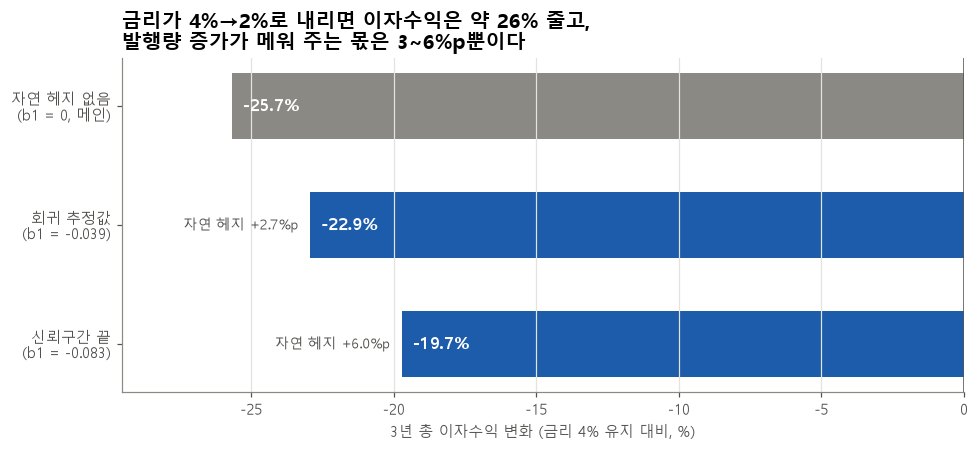

저장: C:\Users\haley\OneDrive\바탕 화면\stablecoin-floor\output\figures\final\1_natural_hedge.png


In [3]:
B1 = {"자연 헤지 없음\n(b1 = 0, 메인)": 0.0, "회귀 추정값\n(b1 = -0.039)": -0.0394, "신뢰구간 끝\n(b1 = -0.083)": -0.0831}
months = 36
dgs2_path = np.linspace(0, -2.0, months + 1)[1:]
rate_path = np.linspace(4.0, 2.0, months + 1)[1:]
base_total = 100 * 0.04 * 3

changes = {}
for name, b in B1.items():
    R_path = 100 * np.exp(b * dgs2_path)
    changes[name] = (np.sum(R_path * rate_path / 100 / 12) / base_total - 1) * 100

fig, ax = plt.subplots(figsize=(9, 4.2))
names = list(changes)
values = np.array(list(changes.values()))
bars = ax.barh(names, values, color=[GREY, BLUE, BLUE], height=0.55)
for bar, v in zip(bars, values):
    ax.text(v + 0.4, bar.get_y() + bar.get_height() / 2, f"{v:.1f}%", va="center", ha="left", color="white",
            fontsize=11, fontweight="bold")                       # 막대 안쪽 왼쪽 끝에 값
for i, v in enumerate(values[1:], start=1):
    ax.text(v - 0.4, i, f"자연 헤지 +{v - values[0]:.1f}%p", va="center", ha="right", color=TEXT_SUB, fontsize=9)   # 막대 바깥 왼쪽
ax.axvline(0, color=TEXT_SUB, linewidth=1)
ax.invert_yaxis()
ax.set_xlim(values.min() * 1.15, 0)
ax.grid(axis="y", visible=False)
ax.set_xlabel("3년 총 이자수익 변화 (금리 4% 유지 대비, %)")
ax.set_title("금리가 4%→2%로 내리면 이자수익은 약 26% 줄고,\n발행량 증가가 메워 주는 몫은 3~6%p뿐이다", loc="left")
fig.tight_layout()
save(fig, "1_natural_hedge.png")

## 그림 2. 금리 시나리오 (방법 설명용)
이 셀이 하는 일: 시장 선도금리(진한 선)와 시뮬레이션 경로 1만 개의 퍼짐(바깥 = 5~95%, 안쪽 = 25~75%)을 팬 차트로 그린다.
- **팬 차트**: 시간이 갈수록 넓어지는 부채꼴 모양의 범위 그래프. 미래가 멀수록 불확실성이 커진다는 것을 보여준다.

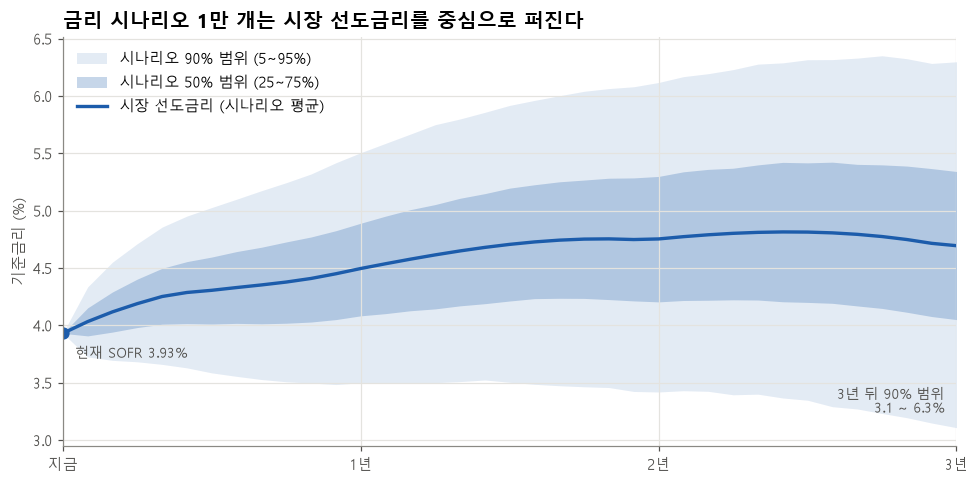

저장: C:\Users\haley\OneDrive\바탕 화면\stablecoin-floor\output\figures\final\2_rate_paths.png


In [4]:
t = np.arange(paths.shape[1])
p5, p25, p75, p95 = np.percentile(paths, [5, 25, 75, 95], axis=0)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.fill_between(t, p5, p95, color=BLUE, alpha=0.12, linewidth=0, label="시나리오 90% 범위 (5~95%)")
ax.fill_between(t, p25, p75, color=BLUE, alpha=0.25, linewidth=0, label="시나리오 50% 범위 (25~75%)")
ax.plot(t, market["fwd"], color=BLUE, linewidth=2.2, label="시장 선도금리 (시나리오 평균)")
ax.plot(0, market["sofr"], "o", color=BLUE, markersize=7)
ax.annotate(f"현재 SOFR {market['sofr']:.2f}%", (0, market["sofr"]), xytext=(8, -16), textcoords="offset points",
            color=TEXT_SUB, fontsize=9)
ax.annotate(f"3년 뒤 90% 범위\n{p5[-1]:.1f} ~ {p95[-1]:.1f}%", (36, p5[-1]), xytext=(-8, 8), textcoords="offset points",
            ha="right", va="bottom", color=TEXT_SUB, fontsize=9)
ax.set_xlim(0, 36)
ax.set_xticks([0, 12, 24, 36])
ax.set_xticklabels(["지금", "1년", "2년", "3년"])
ax.set_ylabel("기준금리 (%)")
ax.set_title("금리 시나리오 1만 개는 시장 선도금리를 중심으로 퍼진다", loc="left")
ax.legend(loc="upper left")
fig.tight_layout()
save(fig, "2_rate_paths.png")

## 그림 3. 규모별 효율적 투자선 (메시지 3·4)
이 셀이 하는 일: 세 규모의 25개 전략을 같은 축 범위로 나란히 그린다. 점 색은 만기(회색 = 무헤지, 파랑 = 3년, 주황 = 1년 롤링), 선은 효율적 투자선, ★는 최적 정책, 빨간 점선은 손실확률 5% 기준이다. 비용은 억 달러 단위.

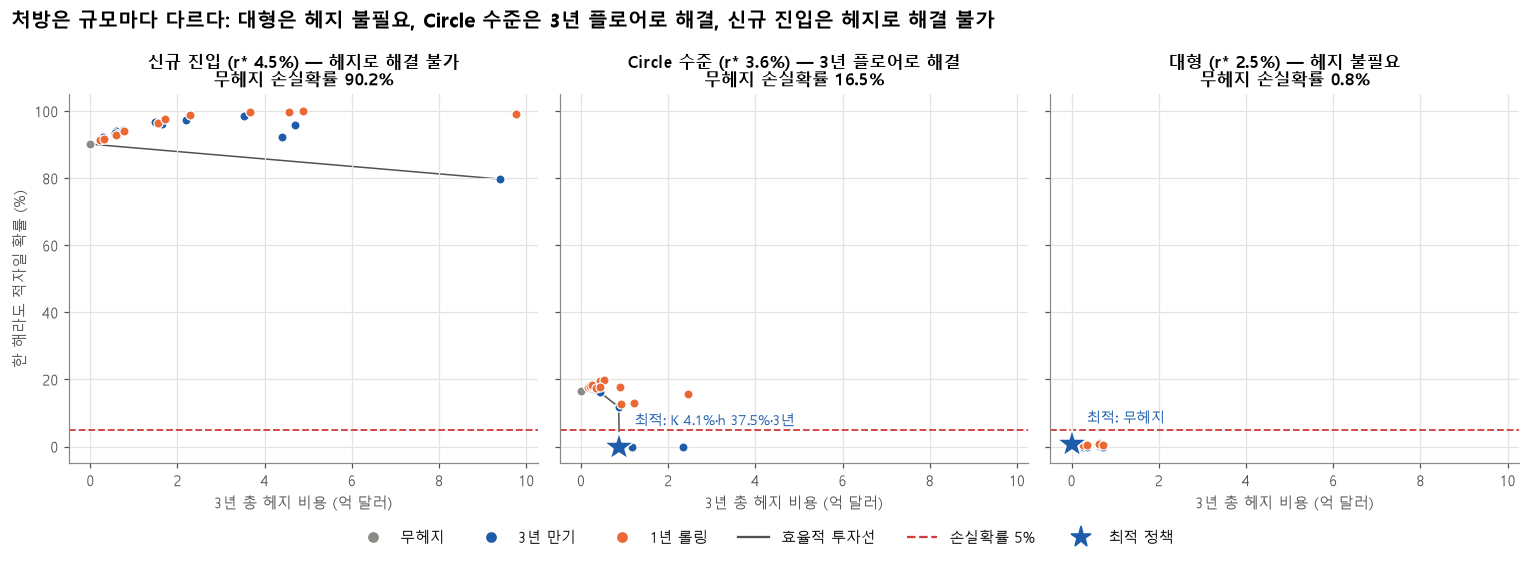

저장: C:\Users\haley\OneDrive\바탕 화면\stablecoin-floor\output\figures\final\3_frontier_by_size.png


In [5]:
def efficient_mask(df):
    cost, loss = df["총 헤지 비용(백만$)"].to_numpy(), df["손실확률(%)"].to_numpy()
    return np.array([not ((cost <= cost[i]) & (loss <= loss[i]) & ((cost < cost[i]) | (loss < loss[i]))).any()
                     for i in range(len(df))])

TENOR_COLOR = {None: GREY, "3년": BLUE, "1년 롤링": ORANGE}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), sharex=True, sharey=True)
verdict_text = {"신규 진입": "헤지로 해결 불가", "Circle 수준": "3년 플로어로 해결", "대형": "헤지 불필요"}
for ax, size in zip(axes, RSTAR):
    res = results[size].copy()
    res["비용(억$)"] = res["총 헤지 비용(백만$)"] / 100
    eff = res[efficient_mask(res)].sort_values("비용(억$)")
    ax.plot(eff["비용(억$)"], eff["손실확률(%)"], color=TEXT_SUB, linewidth=1, zorder=1)
    for tenor, color in TENOR_COLOR.items():
        sub = res[res["만기"].isna()] if tenor is None else res[res["만기"] == tenor]
        ax.scatter(sub["비용(억$)"], sub["손실확률(%)"], s=36, color=color, edgecolor="white", linewidth=0.8, zorder=2)
    best = pick_optimal(res)
    if best is not None:
        ax.plot(best["총 헤지 비용(백만$)"] / 100, best["손실확률(%)"], marker="*", markersize=20, color=BLUE,
                markeredgecolor="white", zorder=3)
        label = "최적: 무헤지" if best["전략"] == "무헤지" else f"최적: K {best['K']:.1f}%·h {best['h'] * 100:g}%·3년"
        ax.annotate(label, (best["총 헤지 비용(백만$)"] / 100, best["손실확률(%)"]), xytext=(10, 14),
                    textcoords="offset points", fontsize=9, color=BLUE)
    ax.axhline(5, color=RED, linestyle="--", linewidth=1.2)
    unh = res.loc[res["전략"] == "무헤지", "손실확률(%)"].iloc[0]
    ax.set_title(f"{size} (r* {RSTAR[size]}%) — {verdict_text[size]}\n무헤지 손실확률 {unh:.1f}%", fontsize=11)
    ax.set_xlabel("3년 총 헤지 비용 (억 달러)")
axes[0].set_ylabel("한 해라도 적자일 확률 (%)")
handles = [Line2D([], [], marker="o", linestyle="none", color=c, label=l)
           for c, l in [(GREY, "무헤지"), (BLUE, "3년 만기"), (ORANGE, "1년 롤링")]]
handles += [Line2D([], [], color=TEXT_SUB, label="효율적 투자선"), Line2D([], [], color=RED, linestyle="--", label="손실확률 5%"),
            Line2D([], [], marker="*", linestyle="none", markersize=14, color=BLUE, label="최적 정책")]
fig.legend(handles=handles, loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("처방은 규모마다 다르다: 대형은 헤지 불필요, Circle 수준은 3년 플로어로 해결, 신규 진입은 헤지로 해결 불가",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "3_frontier_by_size.png")

## 그림 4. 1년 롤링 vs 3년 만기 (메시지 3)
이 셀이 하는 일: Circle 수준의 최적 조합(K·h)으로 무헤지·1년 롤링·3년 만기의 **해별 적자확률**과 **한 해라도 적자일 확률**을, 메인 세계와 세계 C(금리가 1.32%로 끌려가는 스트레스)로 나란히 그린다.

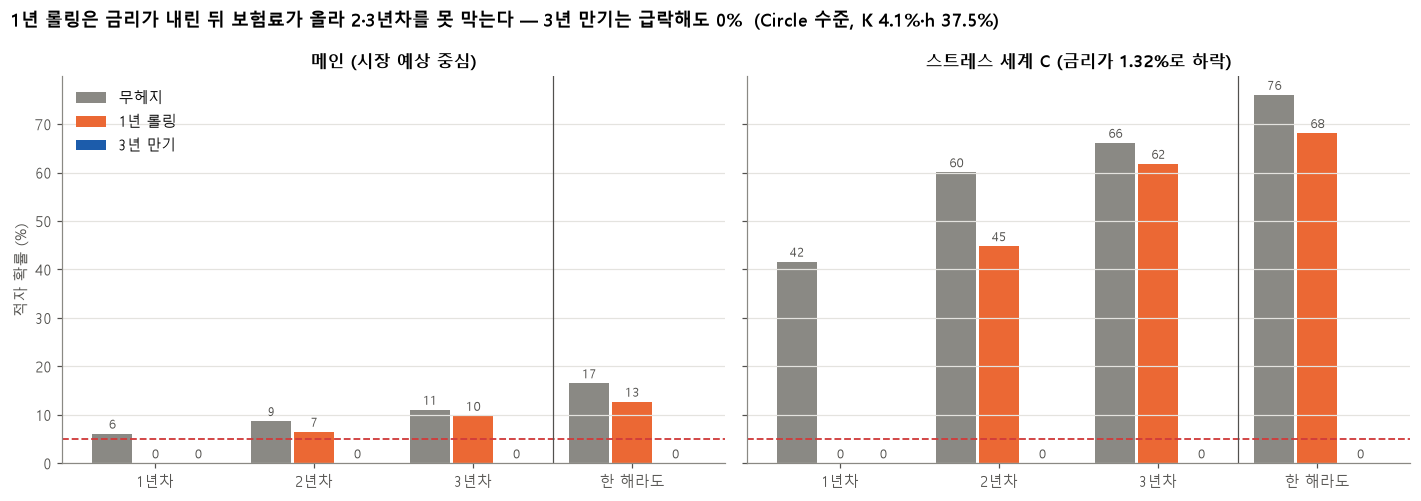

저장: C:\Users\haley\OneDrive\바탕 화면\stablecoin-floor\output\figures\final\4_roll_vs_3y.png


In [6]:
pair = best_circle["전략"]
roll = pair.replace("3년", "1년 롤링")
SERIES = [("무헤지", "무헤지", GREY), ("1년 롤링", roll, ORANGE), ("3년 만기", pair, BLUE)]
GROUPS = ["1년차", "2년차", "3년차", "한 해라도"]


def year_probs(annual):
    return [(annual[:, y] < 0).mean() * 100 for y in range(3)] + [(annual < 0).any(axis=1).mean() * 100]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, (title, ann) in zip(axes, [("메인 (시장 예상 중심)", annual_main), ("스트레스 세계 C (금리가 1.32%로 하락)", annual_c)]):
    x = np.arange(len(GROUPS))
    for i, (label, key, color) in enumerate(SERIES):
        vals = year_probs(ann[key])
        bars = ax.bar(x + (i - 1) * 0.27, vals, width=0.25, color=color, label=label)
        for bar, v in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2, v + 1, f"{v:.0f}", ha="center", fontsize=8, color=TEXT_SUB)
    ax.axhline(5, color=RED, linestyle="--", linewidth=1.2)
    ax.axvline(2.5, color=TEXT_SUB, linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(GROUPS)
    ax.grid(axis="x", visible=False)
    ax.set_title(title, fontsize=11)
axes[0].set_ylabel("적자 확률 (%)")
axes[0].legend(loc="upper left")
k_txt, h_txt = best_circle["K"], best_circle["h"] * 100
fig.suptitle(f"1년 롤링은 금리가 내린 뒤 보험료가 올라 2·3년차를 못 막는다 — 3년 만기는 급락해도 0%  "
             f"(Circle 수준, K {k_txt:.1f}%·h {h_txt:g}%)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
save(fig, "4_roll_vs_3y.png")

## 그림 5. 강건성 (○/× 표)
이 셀이 하는 일: 06번에서 저장한 설정별 판정(`robustness_verdict.csv`)을 표 그림으로 만든다. ○ = 결론 유지, × = 뒤집힘, — = 판단 대상 없음(헤지가 필요 없는 경우).

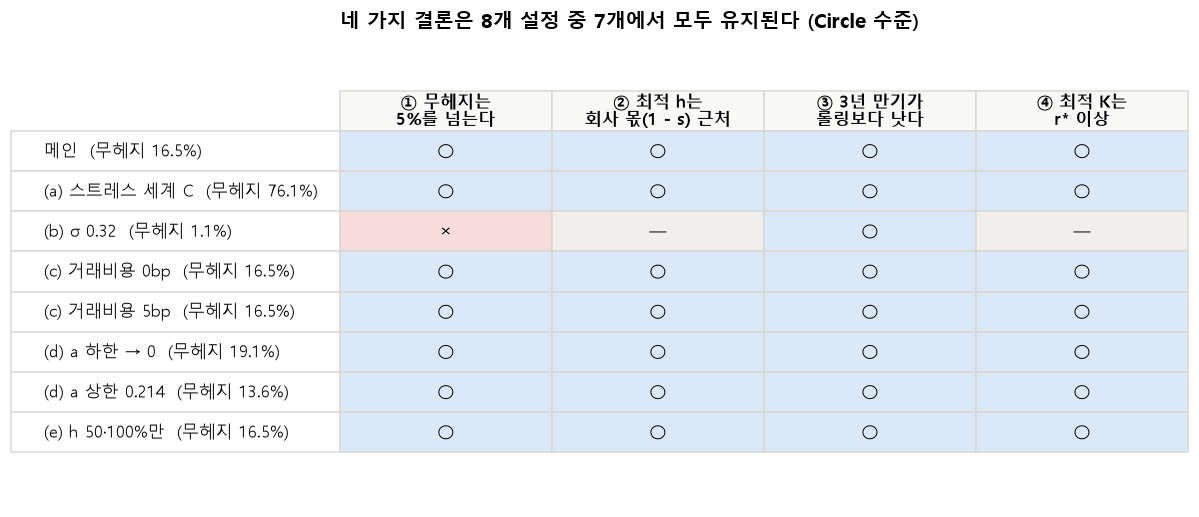

저장: C:\Users\haley\OneDrive\바탕 화면\stablecoin-floor\output\figures\final\5_robustness.png


In [7]:
verdict = pd.read_csv(PROC_DIR / "robustness_verdict.csv", index_col=0)
cols = ["①", "②", "③", "④"]
col_names = ["① 무헤지는\n5%를 넘는다", "② 최적 h는\n회사 몫(1 - s) 근처", "③ 3년 만기가\n롤링보다 낫다", "④ 최적 K는\nr* 이상"]
held = sum((verdict.loc[i, cols] == "○").all() for i in verdict.index)

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.axis("off")
cell_text = verdict[cols].values.tolist()
row_labels = [f"{i}  (무헤지 {verdict.loc[i, '무헤지(%)']:.1f}%)" for i in verdict.index]
table = ax.table(cellText=cell_text, rowLabels=row_labels, colLabels=col_names, cellLoc="center", loc="center")
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.9)
MARK_COLOR = {"○": "#dbe8f8", "×": "#f8dcdc", "—": "#f0efec"}
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("#d9d8d4")
    if row == 0:
        cell.set_text_props(fontweight="bold")
        cell.set_facecolor("#f9f9f7")
    elif col >= 0:
        cell.set_facecolor(MARK_COLOR.get(cell.get_text().get_text(), "white"))
ax.set_title(f"네 가지 결론은 {len(verdict)}개 설정 중 {held}개에서 모두 유지된다 (Circle 수준)",
             loc="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "5_robustness.png")